# Training points

Each watershed's forest learns from presence points, NOAA Storm Events reports of Flood or
Flash Flood, and an equal number of pseudo-absence points sampled the way Collins et al. (2022)
describe: matched to the presences by HUC-2 watershed and land-cover class, outside the
combined 100-year floodplain, and off presence cells. Three point sets are compared here:

| run | points |
| --- | --- |
| `original` | the released points of Collins et al. (2022), December 2006–May 2020 |
| `noaa-200612-202005` | rebuilt from NOAA over the released window |
| `noaa-200612-202512` | rebuilt from NOAA through December 2025; the served model |

Code: `input-data/tensor/fdp/fdp_points.py`. Each run's `points.json` under
`s3://carbonplan-ocr/input/flood/fdp-refit/runs/` records its counts and the NOAA files with
their hashes.

In [1]:
import json

import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REFIT = 's3://carbonplan-ocr/input/flood/fdp-refit'
RUN = 'noaa-200612-202512'
HUCS = [f'{i:02d}' for i in range(1, 19)]
NAMES = {
    '01': 'New England',
    '02': 'Mid Atlantic',
    '03': 'South Atlantic-Gulf',
    '04': 'Great Lakes',
    '05': 'Ohio',
    '06': 'Tennessee',
    '07': 'Upper Mississippi',
    '08': 'Lower Mississippi',
    '09': 'Souris-Red-Rainy',
    '10': 'Missouri',
    '11': 'Arkansas-White-Red',
    '12': 'Texas-Gulf',
    '13': 'Rio Grande',
    '14': 'Upper Colorado',
    '15': 'Lower Colorado',
    '16': 'Great Basin',
    '17': 'Pacific Northwest',
    '18': 'California',
}
fs = fsspec.filesystem('s3')


def record(path):
    return json.loads(fs.cat_file(f'{REFIT}/{path}'))


BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#9aa5b1'
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)
pd.set_option('display.max_rows', 40)

POINTS = {run: record(f'runs/{run}/points.json') for run in ('original', 'noaa-200612-202005', RUN)}

## 1. From reports to points

A presence is the first report in each 100 m cell, at the report's begin coordinates. Every
CONUS report lands on the grid; the presences that outnumber the absences are those whose
cell has no land-cover class, so no class to match an absence to.

In [2]:
rows = {}
for run in ('noaa-200612-202005', RUN):
    p = POINTS[run]
    rows[run] = {
        **p['counts'],
        'presence': p['points']['presence'],
        'absence': p['points']['absence'],
    }
    assert (
        p['points']['presence'] - p['points']['absence']
        == p['counts']['presence_without_land_cover']
    )
rows['original'] = {k: POINTS['original']['points'][k] for k in ('presence', 'absence')}
pd.DataFrame(rows).loc[
    [
        'reports',
        'conus',
        'on_grid',
        'unique_cells',
        'presence_without_land_cover',
        'presence',
        'absence',
    ]
].style.format('{:,.0f}', na_rep='')

,noaa-200612-202005,noaa-200612-202512,original
reports,"86,962","123,616",
conus,"84,987","120,082",
on_grid,"84,987","120,082",
unique_cells,"72,558","103,331",
presence_without_land_cover,251,355,
presence,"72,558","103,331","71,434"
absence,"72,307","102,976","71,434"


## 2. The rebuilt points match the released ones

Over the released window the rebuilt presences cover 99.6% of the released presence cells.

In [3]:
check = POINTS[RUN]['released_window_check']
print(f'rebuilt cells, Dec 2006–May 2020: {check["rebuilt_cells_dec2006_may2020"]:,}')
print(f'released presence cells:          {check["released_cells"]:,}')
print(f'in both:                          {check["overlap"]:,}')
print(f'share of released cells rebuilt:  {check["overlap"] / check["released_cells"]:.1%}')
audit = POINTS['original']['audit']
print(
    f'released absences in the floodplain: {audit["absence_in_floodplain"]}, '
    f'on a presence cell: {audit["absence_on_presence_cell"]}; '
    f'watershed × land-cover groups with equal counts: {audit["huc_class_groups_equal"]} of {audit["huc_class_groups"]}'
)

rebuilt cells, Dec 2006–May 2020: 72,558
released presence cells:          71,434
in both:                          71,147
share of released cells rebuilt:  99.6%
released absences in the floodplain: 0, on a presence cell: 21; watershed × land-cover groups with equal counts: 85 of 111


## 3. Presences by watershed

Adding June 2020–December 2025 raises the presence count by 42% overall, from 18% in
Missouri to 89% in California. The served model trains on the `noaa-200612-202512` column.

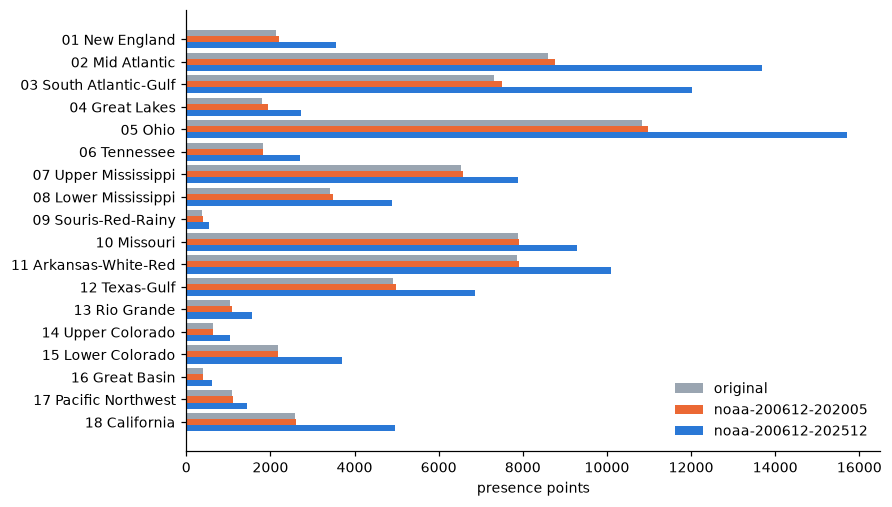

,original,noaa-200612-202005,noaa-200612-202512,added
01 New England,"2,142","2,210","3,562",+61%
02 Mid Atlantic,"8,607","8,769","13,696",+56%
03 South Atlantic-Gulf,"7,306","7,494","12,029",+61%
04 Great Lakes,"1,812","1,939","2,729",+41%
05 Ohio,"10,823","10,976","15,711",+43%
06 Tennessee,"1,815","1,829","2,709",+48%
07 Upper Mississippi,"6,532","6,583","7,885",+20%
08 Lower Mississippi,"3,418","3,485","4,900",+41%
09 Souris-Red-Rainy,378,405,548,+35%
10 Missouri,"7,880","7,911","9,297",+18%


In [4]:
by_huc = pd.DataFrame(
    {run: {h: v['presence'] for h, v in POINTS[run]['points']['by_huc'].items()} for run in POINTS}
).loc[HUCS]
by_huc['added'] = by_huc[RUN] / by_huc['noaa-200612-202005'] - 1
by_huc.index = [f'{h} {NAMES[h]}' for h in by_huc.index]
fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
y = np.arange(len(by_huc))
for i, (run, color) in enumerate(zip(POINTS, [GRAY, ORANGE, BLUE])):
    ax.barh(y + (i - 1) * 0.27, by_huc[run], height=0.27, color=color, label=run)
ax.set(yticks=y, yticklabels=by_huc.index, xlabel='presence points')
ax.invert_yaxis()
ax.legend(frameon=False)
plt.show()
by_huc.style.format({c: '{:,.0f}' for c in POINTS} | {'added': '{:+.0%}'})

In [5]:
print(
    f'added presences, all watersheds: {by_huc[RUN].sum() / by_huc["noaa-200612-202005"].sum() - 1:+.0%}'
)
print(f'range across watersheds: {by_huc["added"].min():+.0%} to {by_huc["added"].max():+.0%}')

added presences, all watersheds: +42%
range across watersheds: +18% to +89%
